# 04. Đánh giá Toàn diện Mô hình & Tổng hợp Báo cáo
**Đề tài:** Dự đoán khả năng khách hàng hủy đặt phòng khách sạn (*Hotel Booking Demand*)

## Quy trình Đánh giá (Evaluation Workflow)
Notebook này chỉ thực hiện **đánh giá độc lập (Evaluation Only)** — tuyệt đối không đọc tập huấn luyện (`train_strat.csv`, `train_oot.csv`) và không huấn luyện lại bất kỳ mô hình nào (`0` lệnh `clone`, `fit`, `fit_transform`):
1. **Load Model Artifacts & Test Sets:** Đọc `test_strat.csv`, `test_oot.csv`, `feature_metadata.json` và các model artifacts mới từ Notebook 03.
2. **OOF Threshold Optimization (Độc lập):** Tìm ngưỡng tối ưu F1 riêng cho **Final Stratified Model** (từ `oof_predictions.pkl`) và **Final OOT Model** (từ `oot_oof_predictions.pkl`).
3. **Stratified Holdout Evaluation:** Đánh giá các mô hình đại diện theo `strat_model_registry` và Final Stratified Model trên `test_strat.csv`.
4. **Evaluation Visualizations & Feature Importance:** Cập nhật 6 biểu đồ 300 DPI (`07`–`12`), phân tích Confusion Matrix và Gain Feature Importance tổng hợp theo biến gốc.
5. **Independent OOT Evaluation:** Tải trực tiếp `best_oot_model_pipeline.joblib` để đánh giá trên `test_oot.csv` và lập bảng đối chiếu 4 cấu hình.
6. **Kết luận Học thuật & Hạn chế Nghiên cứu.**

In [1]:
from pathlib import Path
import json
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, accuracy_score, log_loss,
    roc_curve, precision_recall_curve, confusion_matrix
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
FIG_DIR = Path("../eda_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Đọc metadata đặc trưng & metadata hai kịch bản từ Notebook 02 & 03
with (PROCESSED_DIR / "feature_metadata.json").open("r", encoding="utf-8") as f:
    feat_meta = json.load(f)
with (MODELS_DIR / "best_hyperparameters.json").open("r", encoding="utf-8") as f:
    strat_meta = json.load(f)
with (MODELS_DIR / "oot_best_hyperparameters.json").open("r", encoding="utf-8") as f:
    oot_meta = json.load(f)

with (MODELS_DIR / "oof_predictions.pkl").open("rb") as f:
    strat_oof_bundle = pickle.load(f)
with (MODELS_DIR / "oot_oof_predictions.pkl").open("rb") as f:
    oot_oof_bundle = pickle.load(f)

df_cv_strat = pd.read_csv(MODELS_DIR / "cv_benchmark_results.csv")
df_cv_oot = pd.read_csv(MODELS_DIR / "oot_cv_benchmark_results.csv")

target_col = feat_meta["target_col"]
num_cols = feat_meta["num_cols"]
low_card_cols = feat_meta["low_card_cat_cols"]
high_card_cols = feat_meta["high_card_cat_cols"]
feature_cols = num_cols + low_card_cols + high_card_cols
cat_dtypes = {c: str for c in low_card_cols + high_card_cols}

# Chỉ đọc hai tập Test (không đọc Training CSV)
test_strat_df = pd.read_csv(PROCESSED_DIR / "test_strat.csv", dtype=cat_dtypes)
X_test_strat = test_strat_df[feature_cols].copy()
y_test_strat = test_strat_df[target_col].astype(int).values

test_oot_df = pd.read_csv(PROCESSED_DIR / "test_oot.csv", dtype=cat_dtypes)
X_test_oot = test_oot_df[feature_cols].copy()
y_test_oot = test_oot_df[target_col].astype(int).values

best_strat_name = strat_meta["best_overall_model"]
best_oot_name = oot_meta["best_oot_model"]
strat_registry = strat_meta["strat_model_registry"]

best_strat_pipe = joblib.load(MODELS_DIR / "best_model_pipeline.joblib")
best_oot_pipe = joblib.load(MODELS_DIR / "best_oot_model_pipeline.joblib")

print(f"test_strat.csv: {X_test_strat.shape[0]:,} dòng x {X_test_strat.shape[1]} features | Tỷ lệ hủy: {y_test_strat.mean()*100:.2f}%")
print(f"test_oot.csv  : {X_test_oot.shape[0]:,} dòng x {X_test_oot.shape[1]} features | Tỷ lệ hủy: {y_test_oot.mean()*100:.2f}%")
print(f"Final Stratified Model: {best_strat_name} ({type(best_strat_pipe.named_steps['model']).__name__})")
print(f"Final OOT Model       : {best_oot_name} ({type(best_oot_pipe.named_steps['model']).__name__})")

test_strat.csv: 23,842 dòng x 35 features | Tỷ lệ hủy: 37.08%
test_oot.csv  : 22,177 dòng x 35 features | Tỷ lệ hủy: 40.57%
Final Stratified Model: LightGBM (Optuna) (LGBMClassifier)
Final OOT Model       : LightGBM (OOT Optuna) (LGBMClassifier)


## 1. Tối ưu Ngưỡng phân loại Độc lập trên Training OOF
Áp dụng cùng hàm quét ngưỡng $\tau \in [0.10, 0.90]$ (bước nhảy `0.01`) để tối đa hóa **F1-Score** hoàn toàn trên **Out-of-Fold Predictions** của từng tập huấn luyện:
- Ngưỡng $\tau^*_{\text{strat}}$ được chọn từ `oof_predictions.pkl` của **Final Stratified Model**.
- Ngưỡng $\tau^*_{\text{oot}}$ được chọn độc lập từ `oot_oof_predictions.pkl` của **Final OOT Model**.
- Tuyệt đối không sử dụng `test_strat.csv` hoặc `test_oot.csv` để tìm ngưỡng, và không áp dụng chéo ngưỡng giữa hai kịch bản.

,Kịch bản OOF,Ngưỡng,F1,Precision,Recall
0,Stratified OOF (LightGBM (Optuna)),Mặc định (0.50),0.8174,0.8425,0.7937
1,Stratified OOF (LightGBM (Optuna)),Tối ưu OOF (0.40),0.8238,0.8065,0.8419
2,OOT OOF (LightGBM (OOT Optuna)),Mặc định (0.50),0.8278,0.8613,0.7969
3,OOT OOF (LightGBM (OOT Optuna)),Tối ưu OOF (0.42),0.8357,0.8282,0.8432


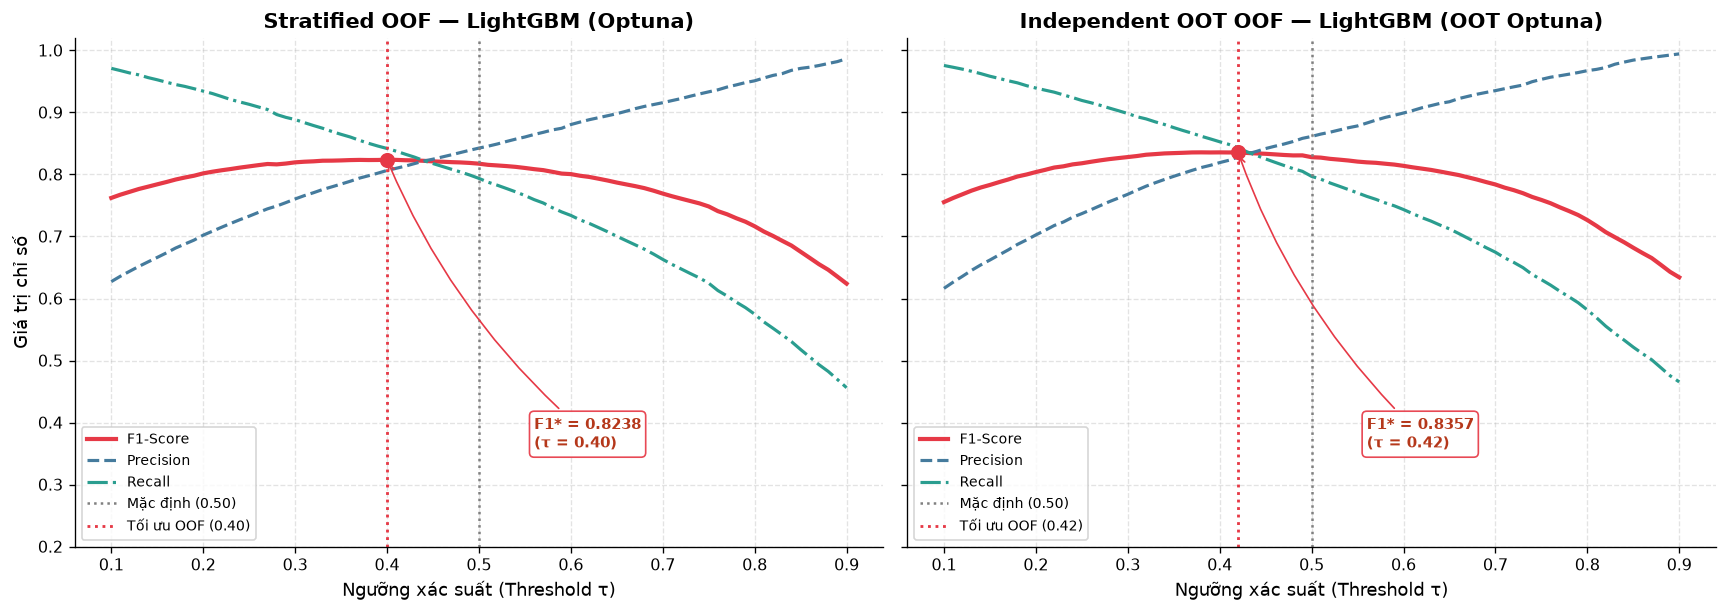

In [2]:
def eval_metrics(y_true, y_proba, threshold: float = 0.50) -> dict:
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),  # Average Precision (AP)
        "f1": f1_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "log_loss": log_loss(y_true, np.clip(y_proba, 1e-7, 1 - 1e-7)),
    }


def find_best_threshold(y_true, y_proba, start: float = 0.10, stop: float = 0.90, step: float = 0.01):
    thresholds = np.round(np.arange(start, stop + step / 2, step), 2)
    rows = []
    for th in thresholds:
        pred = (y_proba >= th).astype(int)
        rows.append({
            "threshold": float(th),
            "f1": f1_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
        })
    df_curve = pd.DataFrame(rows)
    best_row = df_curve.loc[df_curve["f1"].idxmax()]
    default_row = df_curve.loc[df_curve["threshold"] == 0.50].iloc[0]
    return float(best_row["threshold"]), best_row, default_row, df_curve


best_strat_th, strat_th_opt, strat_th_def, df_th_strat = find_best_threshold(
    strat_oof_bundle["y_train"], strat_oof_bundle["oof"][best_strat_name]
)
best_oot_th, oot_th_opt, oot_th_def, df_th_oot = find_best_threshold(
    oot_oof_bundle["y_train"], oot_oof_bundle["oof"][best_oot_name]
)

th_oof_summary = pd.DataFrame([
    {"Kịch bản OOF": f"Stratified OOF ({best_strat_name})", "Ngưỡng": "Mặc định (0.50)", "F1": strat_th_def["f1"], "Precision": strat_th_def["precision"], "Recall": strat_th_def["recall"]},
    {"Kịch bản OOF": f"Stratified OOF ({best_strat_name})", "Ngưỡng": f"Tối ưu OOF ({best_strat_th:.2f})", "F1": strat_th_opt["f1"], "Precision": strat_th_opt["precision"], "Recall": strat_th_opt["recall"]},
    {"Kịch bản OOF": f"OOT OOF ({best_oot_name})", "Ngưỡng": "Mặc định (0.50)", "F1": oot_th_def["f1"], "Precision": oot_th_def["precision"], "Recall": oot_th_def["recall"]},
    {"Kịch bản OOF": f"OOT OOF ({best_oot_name})", "Ngưỡng": f"Tối ưu OOF ({best_oot_th:.2f})", "F1": oot_th_opt["f1"], "Precision": oot_th_opt["precision"], "Recall": oot_th_opt["recall"]},
])
display(th_oof_summary.round(4))

# Biểu đồ 09: Đường cong tối ưu ngưỡng OOF cho Stratified và OOT
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2), sharey=True)
for ax, df_c, th_star, opt_r, title in [
    (axes[0], df_th_strat, best_strat_th, strat_th_opt, f"Stratified OOF — {best_strat_name}"),
    (axes[1], df_th_oot, best_oot_th, oot_th_opt, f"Independent OOT OOF — {best_oot_name}"),
]:
    ax.plot(df_c["threshold"], df_c["f1"], label="F1-Score", color="#e63946", linewidth=2.5)
    ax.plot(df_c["threshold"], df_c["precision"], label="Precision", color="#457b9d", linewidth=1.9, linestyle="--")
    ax.plot(df_c["threshold"], df_c["recall"], label="Recall", color="#2a9d8f", linewidth=1.9, linestyle="-.")
    ax.axvline(0.50, color="gray", linestyle=":", linewidth=1.5, label="Mặc định (0.50)")
    ax.axvline(th_star, color="#e63946", linestyle=":", linewidth=1.7, label=f"Tối ưu OOF ({th_star:.2f})")
    ax.scatter([th_star], [opt_r["f1"]], color="#e63946", s=65, zorder=5)
    ax.annotate(
        f"F1* = {opt_r['f1']:.4f}\n(τ = {th_star:.2f})",
        xy=(th_star, opt_r["f1"]),
        xytext=(0.56, 0.36),
        arrowprops=dict(arrowstyle="->", color="#e63946", connectionstyle="arc3,rad=-0.12"),
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#e63946", alpha=0.92),
        fontsize=9.2, fontweight="bold", color="#b5381b",
    )
    ax.set_title(title)
    ax.set_xlabel("Ngưỡng xác suất (Threshold τ)")
    ax.set_ylim(0.20, 1.02)
    ax.grid(alpha=0.35, linestyle="--")
    ax.legend(loc="lower left", fontsize=8.5)

axes[0].set_ylabel("Giá trị chỉ số")
plt.tight_layout()
fig.savefig(FIG_DIR / "09_threshold_tuning_curve.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## 2. Đánh giá trên Tập Holdout Stratified (`test_strat.csv`)
- **Phân tách vai trò đánh giá:** Điểm **5-Fold CV** ở Notebook 03 dùng cho *Model Selection*; điểm trên `test_strat.csv` dưới đây là **Final Evaluation** độc lập (không dùng Test Score để chọn lại mô hình chiến thắng).
- Các mô hình đại diện được nạp động từ `strat_model_registry` và so sánh nhất quán tại ngưỡng mặc định `0.50`. Riêng **Final Stratified Model** (`best_model_pipeline.joblib`) được đánh giá ở cả ngưỡng `0.50` và ngưỡng tối ưu từ Stratified OOF ($\tau^*_{\text{strat}}$). Lưu ý cột `pr_auc` trong CSV tương ứng với chỉ số **Average Precision (AP)**.

In [3]:
test_rows = []
strat_test_probas = {}
evaluated_names = set()

for entry in strat_registry:
    m_name = entry["model"]
    fname = entry["filename"]
    pipe = joblib.load(MODELS_DIR / fname)
    proba = pipe.predict_proba(X_test_strat)[:, 1]
    strat_test_probas[m_name] = proba
    evaluated_names.add(m_name)

    m = eval_metrics(y_test_strat, proba, threshold=0.50)
    cv_auc = float(df_cv_strat.loc[df_cv_strat["model"] == m_name, "roc_auc_mean"].iloc[0])
    test_rows.append({
        "model": m_name,
        "cv_roc_auc": cv_auc,
        "test_roc_auc": m["roc_auc"],
        "cv_minus_test_auc": cv_auc - m["roc_auc"],
        "test_pr_auc": m["pr_auc"],
        "test_f1_050": m["f1"],
        "test_precision_050": m["precision"],
        "test_recall_050": m["recall"],
        "test_accuracy_050": m["accuracy"],
        "test_log_loss": m["log_loss"],
    })

# Đánh giá trực tiếp Final Stratified Model từ best_model_pipeline.joblib
best_strat_proba = best_strat_pipe.predict_proba(X_test_strat)[:, 1]
strat_test_probas[best_strat_name] = best_strat_proba

# Đảm bảo hoạt động ổn định nếu Final Model không nằm trong strat_model_registry (ví dụ Decision Tree)
if best_strat_name not in evaluated_names:
    m_best_050 = eval_metrics(y_test_strat, best_strat_proba, threshold=0.50)
    cv_auc_best = float(df_cv_strat.loc[df_cv_strat["model"] == best_strat_name, "roc_auc_mean"].iloc[0])
    test_rows.append({
        "model": best_strat_name,
        "cv_roc_auc": cv_auc_best,
        "test_roc_auc": m_best_050["roc_auc"],
        "cv_minus_test_auc": cv_auc_best - m_best_050["roc_auc"],
        "test_pr_auc": m_best_050["pr_auc"],
        "test_f1_050": m_best_050["f1"],
        "test_precision_050": m_best_050["precision"],
        "test_recall_050": m_best_050["recall"],
        "test_accuracy_050": m_best_050["accuracy"],
        "test_log_loss": m_best_050["log_loss"],
    })

df_test_eval = pd.DataFrame(test_rows).sort_values("test_roc_auc", ascending=False).reset_index(drop=True)
df_test_eval.to_csv(MODELS_DIR / "test_evaluation_results.csv", index=False)

display_cols = {
    "model": "Mô hình",
    "cv_roc_auc": "CV ROC-AUC",
    "test_roc_auc": "Test ROC-AUC",
    "cv_minus_test_auc": "CV - Test AUC",
    "test_pr_auc": "Test Average Precision",
    "test_f1_050": "Test F1 (0.50)",
    "test_precision_050": "Precision (0.50)",
    "test_recall_050": "Recall (0.50)",
    "test_accuracy_050": "Accuracy (0.50)",
    "test_log_loss": "Log Loss",
}
print("=== BẢNG ĐÁNH GIÁ CÁC MÔ HÌNH ĐẠI DIỆN TRÊN test_strat.csv (NGƯỠNG 0.50) ===")
display(df_test_eval.rename(columns=display_cols).round(4))

# So sánh riêng Final Stratified Model tại ngưỡng mặc định 0.50 và ngưỡng tối ưu Stratified OOF
m_strat_def = eval_metrics(y_test_strat, best_strat_proba, threshold=0.50)
m_strat_opt = eval_metrics(y_test_strat, best_strat_proba, threshold=best_strat_th)
df_strat_th_comp = pd.DataFrame([
    {"Cấu hình Final Stratified Model": f"{best_strat_name} — Ngưỡng 0.50", **m_strat_def},
    {"Cấu hình Final Stratified Model": f"{best_strat_name} — Ngưỡng OOF ({best_strat_th:.2f})", **m_strat_opt},
]).rename(columns={"pr_auc": "average_precision"})
print(f"\n=== FINAL STRATIFIED MODEL ({best_strat_name}) TRÊN test_strat.csv ===")
display(df_strat_th_comp.round(4))

=== BẢNG ĐÁNH GIÁ CÁC MÔ HÌNH ĐẠI DIỆN TRÊN test_strat.csv (NGƯỠNG 0.50) ===


,Mô hình,CV ROC-AUC,Test ROC-AUC,CV - Test AUC,Test Average Precision,Test F1 (0.50),Precision (0.50),Recall (0.50),Accuracy (0.50),Log Loss
0,LightGBM (Optuna),0.9454,0.9511,-0.0057,0.9283,0.8286,0.8474,0.8106,0.8757,0.2659
1,CatBoost (Optuna),0.9438,0.9485,-0.0047,0.9248,0.8232,0.8440,0.8035,0.8721,0.2722
2,XGBoost (Initial Config),0.9409,0.9459,-0.0050,0.9208,0.8186,0.8430,0.7956,0.8693,0.2803
3,Random Forest (Baseline),0.9321,0.9377,-0.0057,0.9120,0.7759,0.8950,0.6847,0.8533,0.3374
4,Decision Tree (Baseline),0.9199,0.9262,-0.0063,0.8872,0.7900,0.8219,0.7605,0.8501,0.3222
5,Logistic Regression (Baseline),0.9016,0.9112,-0.0096,0.8746,0.7511,0.8113,0.6992,0.8282,0.3504



=== FINAL STRATIFIED MODEL (LightGBM (Optuna)) TRÊN test_strat.csv ===


,Cấu hình Final Stratified Model,roc_auc,average_precision,f1,precision,recall,accuracy,log_loss
0,LightGBM (Optuna) — Ngưỡng 0.50,0.9511,0.9283,0.8286,0.8474,0.8106,0.8757,0.2659
1,LightGBM (Optuna) — Ngưỡng OOF (0.40),0.9511,0.9283,0.8355,0.8106,0.8621,0.8742,0.2659


## 3. Trực quan hóa Đánh giá (Stratified Holdout Test)
Cập nhật 3 nhóm biểu đồ học thuật 300 DPI: so sánh CV vs Test (`07`), đường cong ROC & Precision–Recall (`08`), và Confusion Matrix tại hai ngưỡng quyết định (`10`).

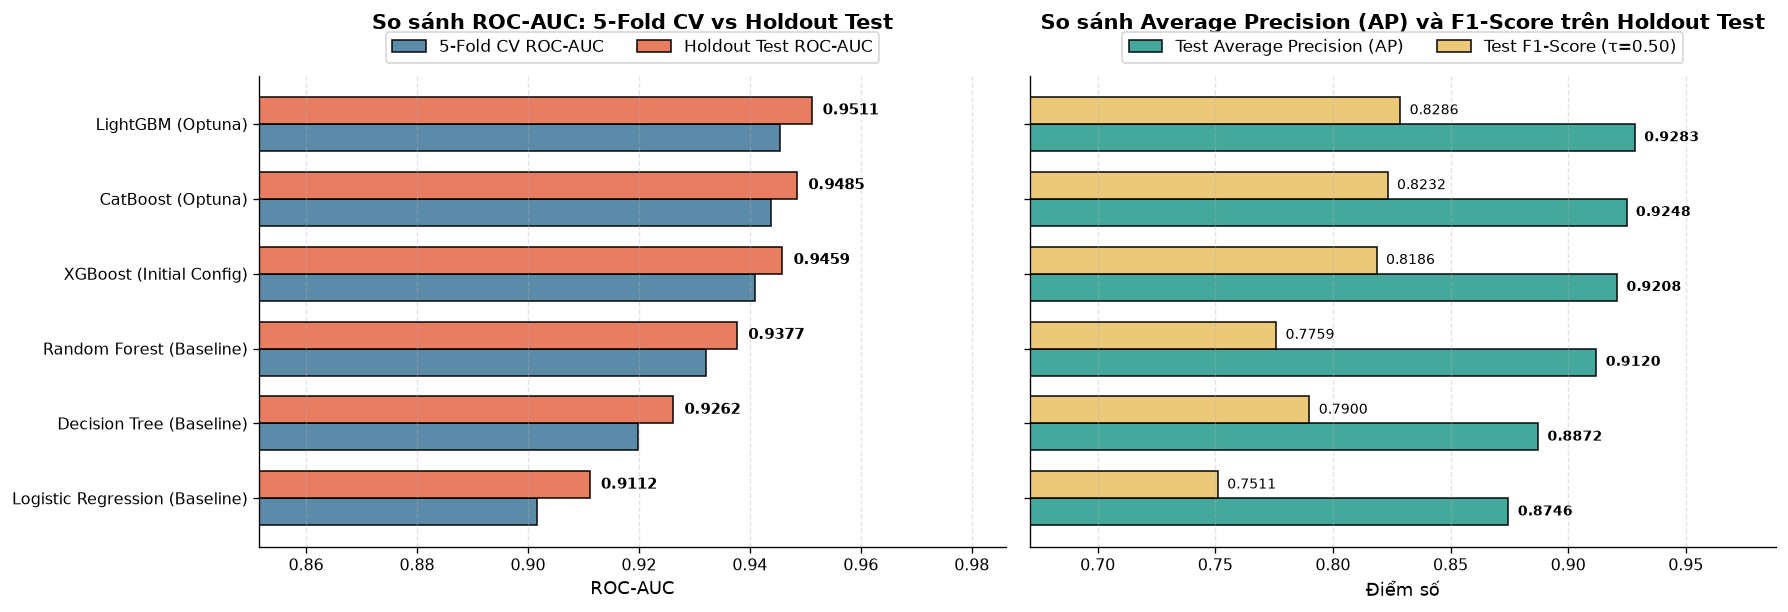

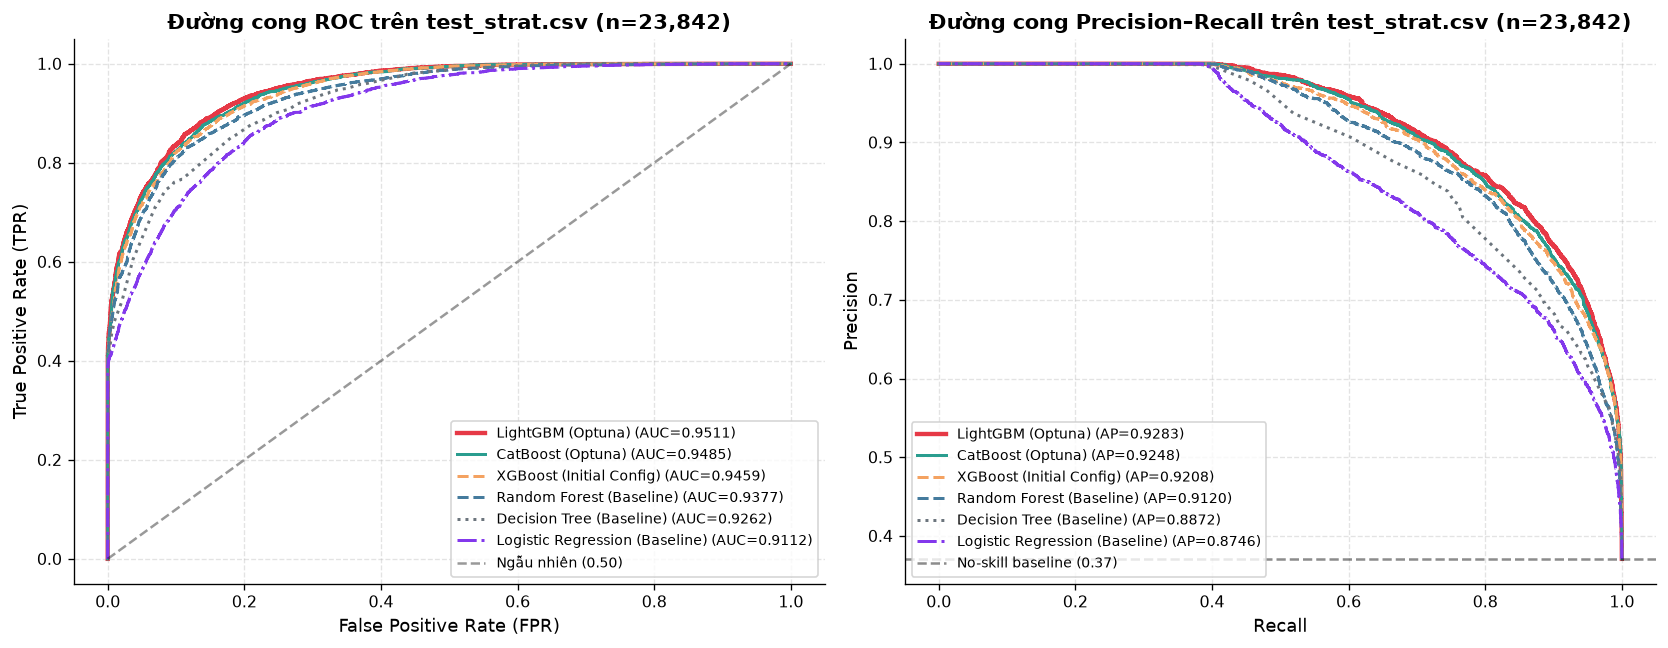

In [4]:
# Biểu đồ 07: So sánh CV vs Test ROC-AUC và Test Average Precision vs F1
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
plot_df = df_test_eval.sort_values("test_roc_auc", ascending=True)
y_pos = np.arange(len(plot_df))
h = 0.36

axes[0].barh(y_pos - h/2, plot_df["cv_roc_auc"], height=h, label="5-Fold CV ROC-AUC", color="#457b9d", edgecolor="black", alpha=0.88)
axes[0].barh(y_pos + h/2, plot_df["test_roc_auc"], height=h, label="Holdout Test ROC-AUC", color="#e76f51", edgecolor="black", alpha=0.9)
for i, (_, r) in enumerate(plot_df.iterrows()):
    axes[0].text(r["test_roc_auc"] + 0.002, i + h/2, f"{r['test_roc_auc']:.4f}", va="center", fontsize=8.8, fontweight="bold")
min_auc = min(plot_df["cv_roc_auc"].min(), plot_df["test_roc_auc"].min())
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_df["model"])
axes[0].set_xlim(max(0.50, min_auc - 0.05), min(1.00, plot_df["test_roc_auc"].max() + 0.035))
axes[0].set_title("So sánh ROC-AUC: 5-Fold CV vs Holdout Test", pad=28)
axes[0].set_xlabel("ROC-AUC")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.11), ncol=2, frameon=True)
axes[0].grid(axis="x", linestyle="--", alpha=0.35)

axes[1].barh(y_pos - h/2, plot_df["test_pr_auc"], height=h, label="Test Average Precision (AP)", color="#2a9d8f", edgecolor="black", alpha=0.88)
axes[1].barh(y_pos + h/2, plot_df["test_f1_050"], height=h, label="Test F1-Score (τ=0.50)", color="#e9c46a", edgecolor="black", alpha=0.9)
for i, (_, r) in enumerate(plot_df.iterrows()):
    axes[1].text(r["test_pr_auc"] + 0.004, i - h/2, f"{r['test_pr_auc']:.4f}", va="center", fontsize=8.6, fontweight="bold")
    axes[1].text(r["test_f1_050"] + 0.004, i + h/2, f"{r['test_f1_050']:.4f}", va="center", fontsize=8.6)
min_ap_f1 = min(plot_df["test_pr_auc"].min(), plot_df["test_f1_050"].min())
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([""] * len(plot_df))
axes[1].set_xlim(max(0.40, min_ap_f1 - 0.08), min(1.02, max(plot_df["test_pr_auc"].max(), plot_df["test_f1_050"].max()) + 0.06))
axes[1].set_title("So sánh Average Precision (AP) và F1-Score trên Holdout Test", pad=28)
axes[1].set_xlabel("Điểm số")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, 1.11), ncol=2, frameon=True)
axes[1].grid(axis="x", linestyle="--", alpha=0.35)

plt.tight_layout()
fig.savefig(FIG_DIR / "07_model_comparison_cv_vs_test.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Biểu đồ 08: Đường cong ROC & Precision-Recall (động theo danh sách mô hình đã đánh giá)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
palette_curves = ["#e63946", "#2a9d8f", "#f4a261", "#457b9d", "#6c757d", "#8338ec"]
line_styles = ["-", "-", "--", "--", ":", "-."]

for idx, m_name in enumerate(df_test_eval["model"].tolist()):
    p = strat_test_probas[m_name]
    color = palette_curves[idx % len(palette_curves)]
    ls = "-" if m_name == best_strat_name else line_styles[idx % len(line_styles)]
    lw = 2.6 if m_name == best_strat_name else 1.8

    fpr, tpr, _ = roc_curve(y_test_strat, p)
    auc_v = roc_auc_score(y_test_strat, p)
    axes[0].plot(fpr, tpr, label=f"{m_name} (AUC={auc_v:.4f})", color=color, linestyle=ls, linewidth=lw)

    prec, rec, _ = precision_recall_curve(y_test_strat, p)
    ap_v = average_precision_score(y_test_strat, p)
    axes[1].plot(rec, prec, label=f"{m_name} (AP={ap_v:.4f})", color=color, linestyle=ls, linewidth=lw)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4, label="Ngẫu nhiên (0.50)")
axes[0].set_title(f"Đường cong ROC trên test_strat.csv (n={len(y_test_strat):,})")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR)")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[0].grid(alpha=0.35, linestyle="--")

axes[1].axhline(y_test_strat.mean(), color="black", linestyle="--", alpha=0.45, label=f"No-skill baseline ({y_test_strat.mean():.2f})")
axes[1].set_title(f"Đường cong Precision–Recall trên test_strat.csv (n={len(y_test_strat):,})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left", fontsize=8.5)
axes[1].grid(alpha=0.35, linestyle="--")

plt.tight_layout()
fig.savefig(FIG_DIR / "08_roc_and_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

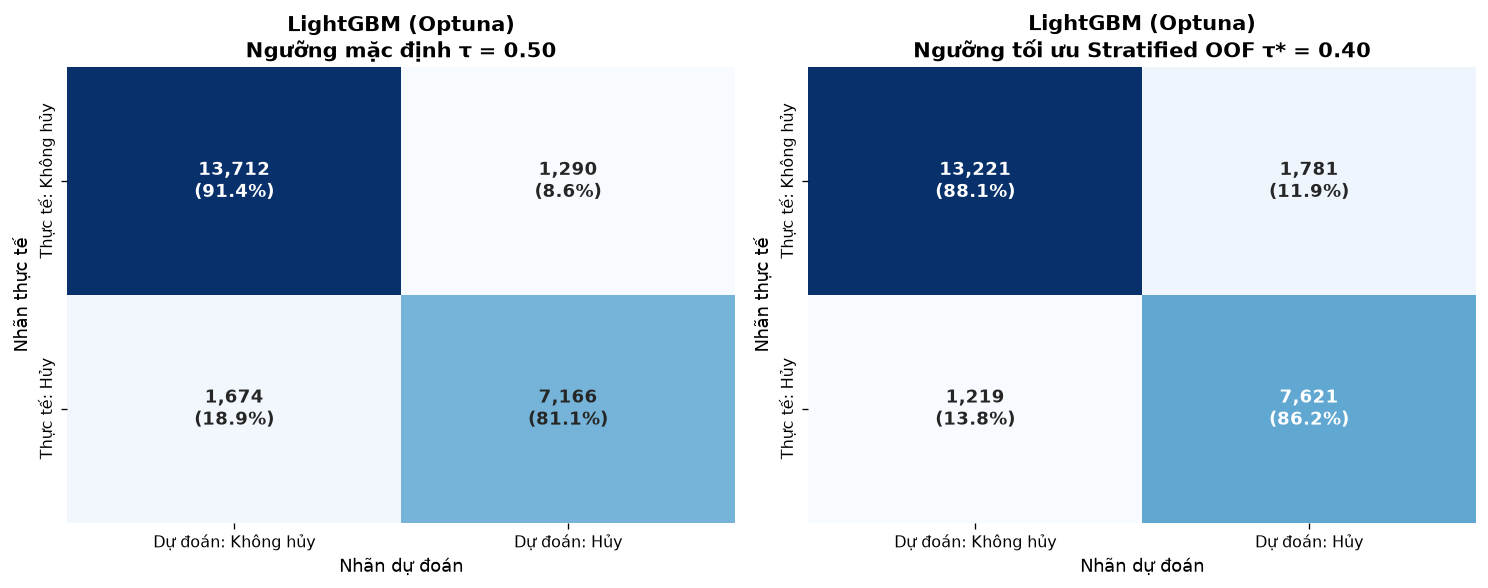

In [5]:
# Biểu đồ 10: Confusion Matrix của Final Stratified Model tại ngưỡng 0.50 vs ngưỡng tối ưu OOF
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, th, label_th in [
    (axes[0], 0.50, "Ngưỡng mặc định τ = 0.50"),
    (axes[1], best_strat_th, f"Ngưỡng tối ưu Stratified OOF τ* = {best_strat_th:.2f}"),
]:
    y_pred = (best_strat_proba >= th).astype(int)
    cm = confusion_matrix(y_test_strat, y_pred)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
    sns.heatmap(
        cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Dự đoán: Không hủy", "Dự đoán: Hủy"],
        yticklabels=["Thực tế: Không hủy", "Thực tế: Hủy"],
        annot_kws={"size": 11, "weight": "bold"},
    )
    ax.set_title(f"{best_strat_name}\n{label_th}")
    ax.set_ylabel("Nhãn thực tế")
    ax.set_xlabel("Nhãn dự đoán")

plt.tight_layout()
fig.savefig(FIG_DIR / "10_confusion_matrix_best_model.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Ý nghĩa của False Positive và False Negative trong bài toán dự đoán hủy phòng:**
- **False Positive (FP — dự đoán hủy nhưng khách thực tế nhận phòng):** Nếu khách sạn dựa vào dự đoán này để bán chồng phòng (*overbooking*) hoặc yêu cầu xác nhận/đặt cọc bổ sung, sẽ phát sinh rủi ro thiếu phòng khi khách đến nhận phòng hoặc làm giảm trải nghiệm khách hàng.
- **False Negative (FN — dự đoán không hủy nhưng khách thực tế hủy):** Khách sạn bỏ sót đơn có nguy cơ hủy cao, dẫn đến phòng trống đột xuất khó kịp bán bù và suy giảm công suất khai thác.
- Do đó, việc chọn ngưỡng $\tau$ thể hiện sự đánh đổi trực tiếp giữa **Precision** (hạn chế FP) và **Recall** (hạn chế FN).

## 4. Độ quan trọng Đặc trưng (Feature Importance — Final Stratified Model)
Sử dụng trực tiếp **Final Stratified Model** (`best_model_pipeline.joblib`):
- Với mô hình cây tăng cường độ dốc (`LightGBM`), ưu tiên **Gain Importance** (tổng mức giảm hàm mất mát đóng góp bởi các nhánh chia sử dụng đặc trưng đó) vì phản ánh chất lượng phân tách tốt hơn so với số lần chia (*split count*).
- Vì bộ tiền xử lý sử dụng `OneHotEncoder`, độ quan trọng của các cột giả (*dummy columns*) được ánh xạ chính xác và cộng dồn về từng **đặc trưng gốc** (`35` features) để dễ diễn giải học thuật, đồng thời in thêm bảng Top 10 đặc trưng ở mức sau mã hóa.
- **Lưu ý:** Feature Importance chỉ đo mức đóng góp vào dự đoán của mô hình trên dữ liệu huấn luyện, **không phải bằng chứng về quan hệ nhân quả**.

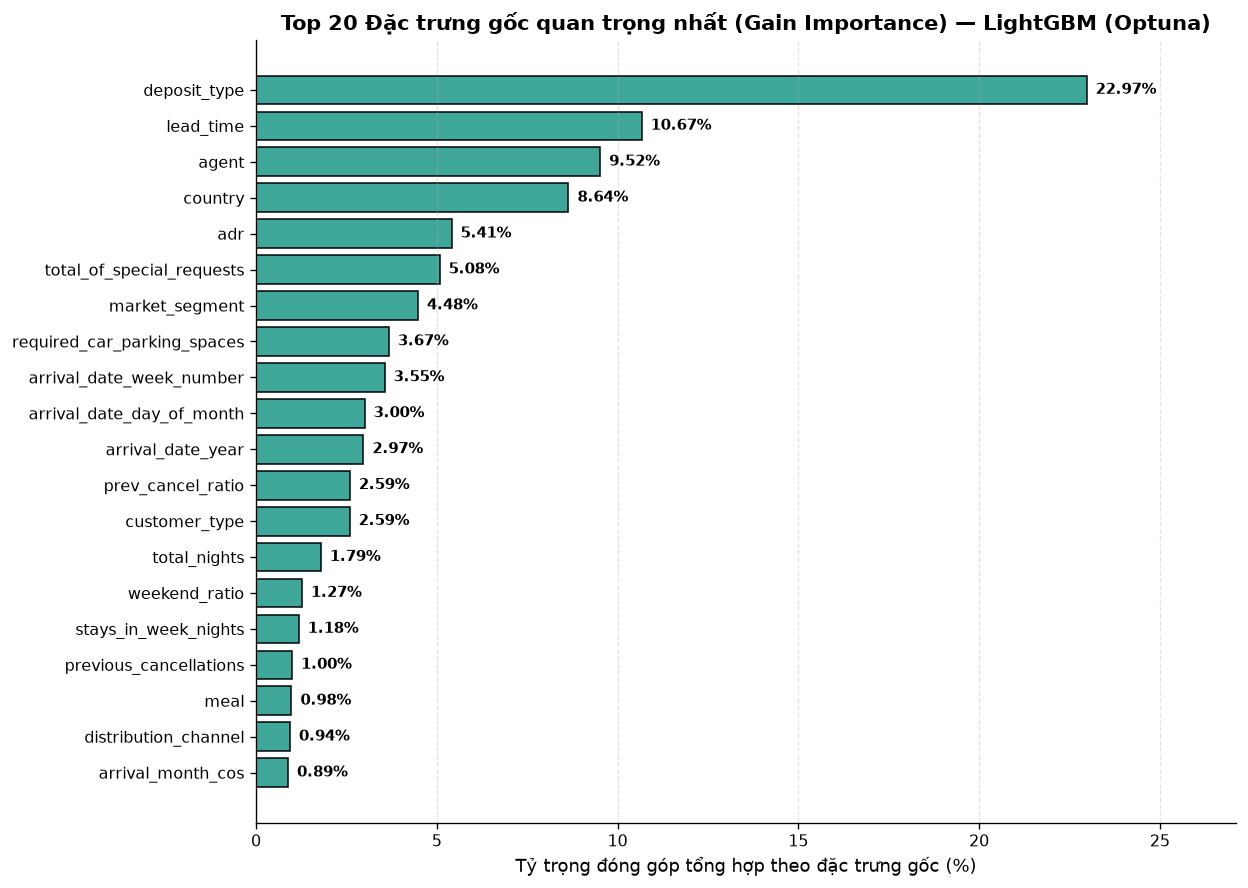

=== Top 10 Đặc trưng gốc (Gain Importance, tổng hợp sau OneHotEncoding) ===


,original_feature,importance_pct
0,deposit_type,22.971
1,lead_time,10.667
2,agent,9.517
3,country,8.642
4,adr,5.408
5,total_of_special_requests,5.078
6,market_segment,4.480
7,required_car_parking_spaces,3.674
8,arrival_date_week_number,3.555
9,arrival_date_day_of_month,3.002



=== Top 10 Đặc trưng ở mức sau mã hóa (Encoded Features) ===


,encoded_feature,original_feature,importance_pct
0,deposit_type_Non Refund,deposit_type,18.201
1,lead_time,lead_time,10.667
2,adr,adr,5.408
3,total_of_special_requests,total_of_special_requests,5.078
4,deposit_type_No Deposit,deposit_type,4.713
5,country_PRT,country,4.539
6,agent_9,agent,3.842
7,required_car_parking_spaces,required_car_parking_spaces,3.674
8,arrival_date_week_number,arrival_date_week_number,3.555
9,arrival_date_day_of_month,arrival_date_day_of_month,3.002


In [6]:
def extract_importance(pipe):
    model_obj = pipe.named_steps["model"]
    if hasattr(model_obj, "booster_"):
        return np.asarray(model_obj.booster_.feature_importance(importance_type="gain"), dtype=float), "Gain Importance"
    if hasattr(model_obj, "get_feature_importance"):
        return np.asarray(model_obj.get_feature_importance(), dtype=float), "CatBoost Importance"
    if hasattr(model_obj, "feature_importances_"):
        return np.asarray(model_obj.feature_importances_, dtype=float), "Tree Feature Importance"
    if hasattr(model_obj, "coef_"):
        return np.abs(np.asarray(model_obj.coef_, dtype=float)).ravel(), "|Coefficient|"
    return None, None


def map_encoded_to_original(enc_name: str, cat_cols_sorted: list[str]) -> str:
    if enc_name.startswith("num__"):
        return enc_name[len("num__"):]
    for prefix in ("low_cat__", "high_cat__"):
        if enc_name.startswith(prefix):
            body = enc_name[len(prefix):]
            for c in cat_cols_sorted:
                if body.startswith(c + "_"):
                    return c
            return body
    return enc_name


imp_vals, imp_method = extract_importance(best_strat_pipe)
raw_feat_names = list(best_strat_pipe.named_steps["preprocessor"].get_feature_names_out())

if imp_vals is not None and len(imp_vals) == len(raw_feat_names) and imp_vals.sum() > 0:
    cat_cols_sorted = sorted(low_card_cols + high_card_cols, key=len, reverse=True)
    df_imp_enc = pd.DataFrame({
        "encoded_feature": [n.replace("num__", "").replace("low_cat__", "").replace("high_cat__", "") for n in raw_feat_names],
        "original_feature": [map_encoded_to_original(n, cat_cols_sorted) for n in raw_feat_names],
        "raw_importance": imp_vals,
    })
    df_imp_enc["importance_pct"] = df_imp_enc["raw_importance"] / df_imp_enc["raw_importance"].sum() * 100

    # Tổng hợp theo đặc trưng gốc sau OneHotEncoding
    df_imp_orig = (
        df_imp_enc.groupby("original_feature", as_index=False)["importance_pct"]
        .sum()
        .sort_values("importance_pct", ascending=False)
        .reset_index(drop=True)
    )

    top_k = min(20, len(df_imp_orig))
    plot_imp = df_imp_orig.head(top_k).iloc[::-1]

    fig, ax = plt.subplots(figsize=(10.5, 7.5))
    bars = ax.barh(plot_imp["original_feature"], plot_imp["importance_pct"], color="#2a9d8f", edgecolor="black", alpha=0.9)
    for bar, val in zip(bars, plot_imp["importance_pct"]):
        ax.text(val + 0.25, bar.get_y() + bar.get_height() / 2, f"{val:.2f}%", va="center", fontsize=8.8, fontweight="bold")
    ax.set_title(f"Top {top_k} Đặc trưng gốc quan trọng nhất ({imp_method}) — {best_strat_name}")
    ax.set_xlabel("Tỷ trọng đóng góp tổng hợp theo đặc trưng gốc (%)")
    ax.set_xlim(0, plot_imp["importance_pct"].max() * 1.18)
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    plt.tight_layout()
    fig.savefig(FIG_DIR / "11_feature_importance_top20.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"=== Top 10 Đặc trưng gốc ({imp_method}, tổng hợp sau OneHotEncoding) ===")
    display(df_imp_orig.head(10).round(3))
    print("\n=== Top 10 Đặc trưng ở mức sau mã hóa (Encoded Features) ===")
    display(df_imp_enc.sort_values("importance_pct", ascending=False)[["encoded_feature", "original_feature", "importance_pct"]].head(10).reset_index(drop=True).round(3))
else:
    print(f"Mô hình {best_strat_name} không hỗ trợ phương pháp trích xuất Feature Importance trực tiếp; bỏ qua biểu đồ.")

## 5. Đánh giá Độc lập theo Thời gian (Independent OOT Evaluation — `test_oot.csv`)
- **Độc lập hoàn toàn với Stratified Experiment:** Tải trực tiếp `best_oot_model_pipeline.joblib` (đã huấn luyện và tinh chỉnh riêng trên `train_oot.csv` ở Notebook 03) và sử dụng ngưỡng $\tau^*_{\text{oot}}$ tối ưu từ `oot_oof_predictions.pkl`.
- **Lưu ý phương pháp:**
  - Tập `test_oot.csv` được chia theo **ngày nhận phòng dự kiến (`arrival_date >= 2017-05-01`)**, không phải ngày xác nhận đặt phòng.
  - Hai kịch bản Stratified và OOT sử dụng **hai mô hình được huấn luyện độc lập trên hai tập train khác nhau**; chênh lệch hiệu năng có thể đến từ nhiều yếu tố (khác biệt thời điểm mùa vụ, phân phối tỷ lệ hủy, cấu trúc tập train) nên **không quy toàn bộ chênh lệch cho Data Drift hay Concept Drift**.

Stratified — CV ROC-AUC: 0.9454 | Test ROC-AUC: 0.9511 (Δ = -0.0057)
OOT        — CV ROC-AUC: 0.9527 | Test ROC-AUC: 0.8945 (Δ = +0.0582)

=== BẢNG TỔNG HỢP 4 CẤU HÌNH ĐÁNH GIÁ (STRATIFIED VS INDEPENDENT OOT) ===


,Kịch bản & Cấu hình,Mô hình,Ngưỡng,roc_auc,average_precision,f1,precision,recall,accuracy,log_loss
0,1. Stratified Test — ngưỡng 0.50,LightGBM (Optuna),0.50,0.9511,0.9283,0.8286,0.8474,0.8106,0.8757,0.2659
1,2. Stratified Test — ngưỡng Stratified OOF (0.40),LightGBM (Optuna),0.40,0.9511,0.9283,0.8355,0.8106,0.8621,0.8742,0.2659
2,3. OOT Test — ngưỡng 0.50,LightGBM (OOT Optuna),0.50,0.8945,0.8533,0.7345,0.7952,0.6825,0.7998,0.3956
3,4. OOT Test — ngưỡng OOT OOF (0.42),LightGBM (OOT Optuna),0.42,0.8945,0.8533,0.7524,0.7674,0.7379,0.8029,0.3956


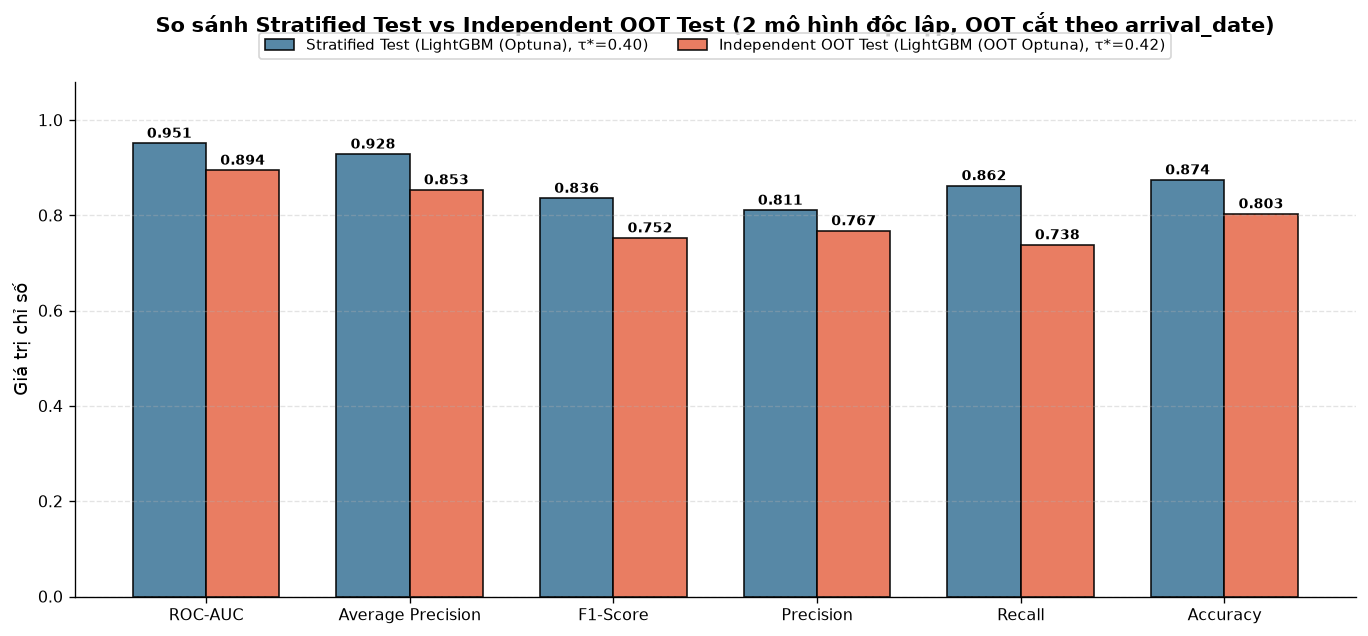

In [7]:
# Dự đoán trực tiếp bằng Final OOT Model (0 lệnh clone/fit)
best_oot_proba = best_oot_pipe.predict_proba(X_test_oot)[:, 1]
m_oot_def = eval_metrics(y_test_oot, best_oot_proba, threshold=0.50)
m_oot_opt = eval_metrics(y_test_oot, best_oot_proba, threshold=best_oot_th)

oot_cv_auc = float(df_cv_oot.loc[df_cv_oot["model"] == best_oot_name, "roc_auc_mean"].iloc[0])
strat_cv_auc = float(df_cv_strat.loc[df_cv_strat["model"] == best_strat_name, "roc_auc_mean"].iloc[0])

print(f"Stratified — CV ROC-AUC: {strat_cv_auc:.4f} | Test ROC-AUC: {m_strat_def['roc_auc']:.4f} (Δ = {strat_cv_auc - m_strat_def['roc_auc']:+.4f})")
print(f"OOT        — CV ROC-AUC: {oot_cv_auc:.4f} | Test ROC-AUC: {m_oot_def['roc_auc']:.4f} (Δ = {oot_cv_auc - m_oot_def['roc_auc']:+.4f})")

# Bảng tổng hợp 4 cấu hình bắt buộc
df_four_configs = pd.DataFrame([
    {"Kịch bản & Cấu hình": "1. Stratified Test — ngưỡng 0.50", "Mô hình": best_strat_name, "Ngưỡng": 0.50, **m_strat_def},
    {"Kịch bản & Cấu hình": f"2. Stratified Test — ngưỡng Stratified OOF ({best_strat_th:.2f})", "Mô hình": best_strat_name, "Ngưỡng": best_strat_th, **m_strat_opt},
    {"Kịch bản & Cấu hình": "3. OOT Test — ngưỡng 0.50", "Mô hình": best_oot_name, "Ngưỡng": 0.50, **m_oot_def},
    {"Kịch bản & Cấu hình": f"4. OOT Test — ngưỡng OOT OOF ({best_oot_th:.2f})", "Mô hình": best_oot_name, "Ngưỡng": best_oot_th, **m_oot_opt},
])
df_four_configs.to_csv(MODELS_DIR / "oot_validation_results.csv", index=False)

print("\n=== BẢNG TỔNG HỢP 4 CẤU HÌNH ĐÁNH GIÁ (STRATIFIED VS INDEPENDENT OOT) ===")
display(df_four_configs.rename(columns={"pr_auc": "average_precision"}).round(4))

# Lưu evaluation_summary.json gọn nhẹ phục vụ báo cáo / demo
eval_summary = {
    "stratified_final": {
        "model": best_strat_name,
        "cv_roc_auc": round(strat_cv_auc, 5),
        "oof_optimal_threshold": best_strat_th,
        "test_metrics_050": {k: round(float(v), 5) for k, v in m_strat_def.items()},
        "test_metrics_oof_opt": {k: round(float(v), 5) for k, v in m_strat_opt.items()},
    },
    "oot_final": {
        "model": best_oot_name,
        "oot_cutoff_arrival_date": feat_meta["split_policy"]["oot_cutoff_date"],
        "cv_roc_auc": round(oot_cv_auc, 5),
        "oof_optimal_threshold": best_oot_th,
        "test_metrics_050": {k: round(float(v), 5) for k, v in m_oot_def.items()},
        "test_metrics_oof_opt": {k: round(float(v), 5) for k, v in m_oot_opt.items()},
    },
}
with (MODELS_DIR / "evaluation_summary.json").open("w", encoding="utf-8") as f:
    json.dump(eval_summary, f, ensure_ascii=False, indent=2)

# Biểu đồ 12: So sánh Stratified Test vs Independent OOT Test (tại ngưỡng tối ưu OOF tương ứng)
metric_keys = ["roc_auc", "pr_auc", "f1", "precision", "recall", "accuracy"]
metric_labels = ["ROC-AUC", "Average Precision", "F1-Score", "Precision", "Recall", "Accuracy"]
strat_vals = [m_strat_opt[k] for k in metric_keys]
oot_vals = [m_oot_opt[k] for k in metric_keys]

x = np.arange(len(metric_keys))
w = 0.36
fig, ax = plt.subplots(figsize=(11.5, 5.4))
b1 = ax.bar(x - w/2, strat_vals, width=w, label=f"Stratified Test ({best_strat_name}, τ*={best_strat_th:.2f})", color="#457b9d", edgecolor="black", alpha=0.9)
b2 = ax.bar(x + w/2, oot_vals, width=w, label=f"Independent OOT Test ({best_oot_name}, τ*={best_oot_th:.2f})", color="#e76f51", edgecolor="black", alpha=0.9)

for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.012, f"{bar.get_height():.3f}", ha="center", fontsize=8.5, fontweight="bold")
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.012, f"{bar.get_height():.3f}", ha="center", fontsize=8.5, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Giá trị chỉ số")
ax.set_title("So sánh Stratified Test vs Independent OOT Test (2 mô hình độc lập, OOT cắt theo arrival_date)", pad=30)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.11), ncol=2, frameon=True, fontsize=8.8)
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
fig.savefig(FIG_DIR / "12_stratified_vs_oot_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## 6. Kết luận Học thuật & Hạn chế Nghiên cứu

### 6.1. Tổng kết kết quả thực nghiệm
1. **Quy trình làm sạch và kiểm soát rò rỉ dữ liệu nhất quán (Notebooks 01–02):**
   - Sau khi loại `181` bản ghi không hợp lệ (`180` dòng tổng khách xác định bằng `0` và `1` dòng `adr < 0`), dữ liệu sạch gồm `119.209` bản ghi (`35` đặc trưng sau khi loại `5` cột leakage gồm `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`, `days_in_waiting_list`; tỷ lệ hủy `37,08%`).
   - Toàn bộ bản ghi trùng lặp hợp lệ được giữ lại thay vì xóa cơ học, đồng thời kiểm soát chồng lấn bằng `StratifiedGroupKFold` theo feature fingerprint (`0` fingerprint overlap giữa Train/Test và giữa các CV folds).
2. **Hiệu quả của Baseline Benchmark, Optuna Tuning và Final Stratified Model (`test_strat.csv`, `n = 23.842`):**
   - Nhóm mô hình cây tăng cường độ dốc (GBDT) đạt hiệu năng vượt trội so với `Logistic Regression (Baseline)` (Test ROC-AUC `0,9112`, Average Precision `0,8747`, F1 `0,7508`) và `Random Forest (Baseline)` (Test ROC-AUC `0,9377`, AP `0,9120`, F1 `0,7759`).
   - Tinh chỉnh Optuna trên Top 2 cải thiện nhẹ CV ROC-AUC cho cả `LightGBM` (`+0,00155`) và `CatBoost` (`+0,00142`), cho thấy tinh chỉnh siêu tham số giúp nâng nhẹ chất lượng mô hình nhưng cần luôn đối chiếu thực nghiệm thay vì mặc định vượt trội.
   - **Final Stratified Model — `LightGBM (Optuna)`** (chọn theo CV ROC-AUC `0,9454`) đạt **Test ROC-AUC `0,9511`**, **Average Precision `0,9283`** và **Log Loss `0,2659`**; mức chênh lệch nhỏ giữa CV và Test cho thấy khả năng tổng quát hóa ổn định trên holdout cùng phân phối thời gian.
3. **Tác động của tối ưu ngưỡng trên Training OOF và đánh đổi Precision–Recall:**
   - Trên `test_strat.csv`, chuyển từ ngưỡng mặc định `0,50` sang ngưỡng tối ưu Stratified OOF (`τ* = 0,40`) giúp **F1-Score** tăng từ `0,8286` lên `0,8355` (`+0,69` điểm phần trăm) và **Recall** tăng từ `81,06%` lên `86,21%` (giảm False Negative từ `1.674` xuống `1.219`), đổi lại **Precision** giảm từ `84,74%` xuống `81,06%` (tăng False Positive từ `1.290` lên `1.781`).
   - Trên `test_oot.csv`, ngưỡng tối ưu độc lập từ OOT OOF (`τ* = 0,42`) giúp **F1-Score** tăng từ `0,7345` lên `0,7524` (`+1,78` điểm phần trăm) và **Recall** tăng từ `68,25%` lên `73,79%` (Precision từ `79,52%` xuống `76,74%`).
4. **Đánh giá khả năng tổng quát hóa theo thời gian (`test_oot.csv`, `n = 22.177`, `arrival_date >= 2017-05-01`):**
   - **Final OOT Model — `LightGBM (OOT Optuna)`** (huấn luyện hoàn toàn độc lập trên `train_oot.csv`, OOT CV ROC-AUC `0,9527`) đạt **OOT Test ROC-AUC `0,8945`** và **Average Precision `0,8533`**.
   - Hiệu năng trên `test_oot.csv` thấp hơn so với OOT CV và Stratified Test (`0,9511`). Đây là quan sát thực nghiệm phản ánh độ khó cao hơn khi dự đoán sang giai đoạn tương lai (nơi tỷ lệ hủy thực tế là `40,57%` so với `36,28%` ở `train_oot.csv`), tuy nhiên do hai kịch bản sử dụng hai mô hình huấn luyện độc lập và rơi vào mùa cao điểm mùa hè, kết quả này **không đủ cơ sở để quy toàn bộ chênh lệch cho Concept Drift hay Data Drift**.

### 6.2. Hạn chế nghiên cứu & Lưu ý khi diễn giải
1. **Rủi ro rò rỉ dữ liệu tiềm ẩn ở các booking features được giữ lại:** Dù đã loại bỏ `5` cột leakage rõ ràng (`reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`, `days_in_waiting_list`), quy trình không thể khẳng định đã loại bỏ tuyệt đối mọi dạng Data Leakage. Đặc biệt, trên biểu đồ Gain Importance, `deposit_type` đóng góp cao nhất (`22,97%`) cùng với `lead_time` (`10,67%`), `agent` (`9,52%`), `country` (`8,64%`), `adr` (`5,41%`), `total_of_special_requests` (`5,08%`). Hiện tượng tỷ lệ hủy rất cao ở nhóm `Non Refund` (~99,4%) là quan sát trên dữ liệu lịch sử và chưa có tài liệu hệ thống xác minh nguyên nhân nghiệp vụ; do đó cần kiểm tra kỹ thời điểm ghi nhận của các biến `deposit_type`, `adr`, `country`, `total_of_special_requests` và `required_car_parking_spaces` trước khi triển khai thực tế.
2. **Định nghĩa mốc chia OOT theo `arrival_date`:** Tập OOT hiện tại được chia theo ngày nhận phòng dự kiến (`2017-05-01`) thay vì ngày xác nhận đặt phòng, nên một số đơn trong `test_oot.csv` có thể đã được tạo trước thời điểm cắt.
3. **Diễn giải Feature Importance:** Gain Importance chỉ phản ánh mức đóng góp phân tách của đặc trưng trong mô hình cây, **không chứng minh quan hệ nhân quả**.
4. **Phạm vi dữ liệu lịch sử (2015–2017):** Bộ dữ liệu chỉ thu thập từ hai khách sạn tại Bồ Đào Nha trong giai đoạn `07/2015–08/2017`, do đó kết quả và mô hình không mặc nhiên tổng quát hóa sang các khách sạn, thị trường hoặc giai đoạn kinh tế–du lịch khác mà cần huấn luyện và thẩm định lại trên dữ liệu mới.